# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Nabila Zahra Alia
- **Email:** bbilazhr@gmail.com
- **ID Dicoding:** bbilazhr

## Menentukan Pertanyaan Bisnis

Olist adalah marketplace Brasil yang menghubungkan seller kecil dengan pelanggan di seluruh negeri. Analisis ini memakai pesanan berstatus **delivered** pada periode **Januari 2017 – Agustus 2018** (periode dengan data yang lengkap; 2016 dan September–Oktober 2018 hanya berisi sangat sedikit pesanan sehingga tidak representatif).

**Definisi metrik:** *revenue* = total `price` item (tidak termasuk ongkos kirim). *Keterlambatan* = pesanan diterima pelanggan setelah `order_estimated_delivery_date`.

1. **Kategori produk apa saja yang menjadi 10 penyumbang revenue terbesar pada pesanan delivered periode Januari 2017 – Agustus 2018, dan berapa persen kontribusinya terhadap total revenue?** *(Aksi: menentukan prioritas akuisisi seller dan alokasi promosi.)*
2. **Bagaimana tren jumlah pesanan dan revenue bulanan (Month-over-Month) selama Januari 2017 – Agustus 2018, serta pada bulan apa terjadi lonjakan tertinggi dan penurunan tertajam?** *(Aksi: merencanakan kampanye dan kapasitas logistik.)*
3. **Di state mana rata-rata waktu pengiriman (hari sejak pembelian hingga diterima) paling lama dan persentase pesanan terlambat paling tinggi pada periode Januari 2017 – Agustus 2018?** *(Aksi: memprioritaskan perbaikan logistik per wilayah.)*

## Menyiapkan semua library yang dibutuhkan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")
def fmt(x, desimal=0):
    # Format angka gaya Indonesia: titik sebagai pemisah ribuan, koma sebagai desimal
    return f"{x:,.{desimal}f}".replace(",", "#").replace(".", ",").replace("#", ".")

pd.set_option("display.float_format", lambda x: fmt(x, 2))

## Data Wrangling

### Gathering Data

Dataset Olist terdiri dari beberapa tabel relasional. Tabel yang dibutuhkan untuk menjawab ketiga pertanyaan:
- `orders`: status & timestamp pesanan
- `order_items`: item, harga, dan ongkos kirim per pesanan
- `customers`: lokasi dan ID unik pelanggan
- `products` + `product_category_name_translation`: kategori produk (Portugis → Inggris)

In [2]:
orders_df = pd.read_csv("data/olist_orders_dataset.csv")
items_df = pd.read_csv("data/olist_order_items_dataset.csv")
customers_df = pd.read_csv("data/olist_customers_dataset.csv")
products_df = pd.read_csv("data/olist_products_dataset.csv")
translation_df = pd.read_csv("data/product_category_name_translation.csv")

for name, d in [("orders", orders_df), ("order_items", items_df), ("customers", customers_df),
                ("products", products_df), ("translation", translation_df)]:
    print(f"{name:12s} -> {fmt(d.shape[0]).rjust(7)} baris, {d.shape[1]} kolom")
orders_df.head()

orders       ->  99.441 baris, 8 kolom
order_items  -> 112.650 baris, 7 kolom
customers    ->  99.441 baris, 5 kolom
products     ->  32.951 baris, 9 kolom
translation  ->      71 baris, 2 kolom


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Terdapat 99.441 pesanan, 112.650 item pesanan, dan 99.441 baris pelanggan (satu baris per `customer_id`, bukan per orang).
- Tabel `orders` menyimpan timestamp sebagai teks sehingga perlu dikonversi sebelum dihitung.
- Relasi antar tabel: `orders.customer_id → customers`, `order_items.order_id → orders`, `order_items.product_id → products`.

### Assessing Data

Pada tahap ini kualitas tiap tabel dinilai: tipe data, missing value, duplikat, nilai tidak valid, outlier, dan inkonsistensi.

In [3]:
print("=== Missing value per tabel ===")
for name, d in [("orders", orders_df), ("order_items", items_df), ("customers", customers_df), ("products", products_df)]:
    miss = d.isna().sum()
    print(f"\n[{name}]")
    print(miss[miss > 0] if miss.sum() > 0 else "tidak ada missing value")

print("\n=== Duplicate data ===")
for name, d in [("orders", orders_df), ("order_items", items_df), ("customers", customers_df),
                ("products", products_df), ("translation", translation_df)]:
    print(f"{name:12s}: {d.duplicated().sum()} baris duplikat")

print("\n=== Tipe data kolom tanggal pada orders ===")
print(orders_df.dtypes)

=== Missing value per tabel ===

[orders]
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

[order_items]
tidak ada missing value

[customers]
tidak ada missing value

[products]
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

=== Duplicate data ===
orders      : 0 baris duplikat
order_items : 0 baris duplikat


customers   : 0 baris duplikat
products    : 0 baris duplikat
translation : 0 baris duplikat

=== Tipe data kolom tanggal pada orders ===
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


In [4]:
print("Distribusi status pesanan:")
print(orders_df["order_status"].value_counts())

delivered = orders_df[orders_df["order_status"] == "delivered"]
print("\nPesanan 'delivered' tanpa tanggal diterima pelanggan:", delivered["order_delivered_customer_date"].isna().sum())
print("Pesanan 'delivered' tanpa tanggal approval        :", delivered["order_approved_at"].isna().sum())

purchase = pd.to_datetime(orders_df["order_purchase_timestamp"])
carrier = pd.to_datetime(orders_df["order_delivered_carrier_date"])
print("Pesanan dengan tanggal serah ke kurir SEBELUM tanggal pembelian:", (carrier < purchase).sum())

print("\nSebaran bulanan pesanan (data tidak lengkap di ujung periode):")
print(purchase.dt.to_period("M").value_counts().sort_index().head(4))
print("...")
print(purchase.dt.to_period("M").value_counts().sort_index().tail(3))
print(f"\nJumlah pesanan pada 2016: {(purchase.dt.year == 2016).sum()} (pada Oktober 2016: {((purchase.dt.year == 2016) & (purchase.dt.month == 10)).sum()})")
print(f"Jumlah pesanan pada September–Oktober 2018: {((purchase >= '2018-09-01') & (purchase < '2018-11-01')).sum()}")

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Pesanan 'delivered' tanpa tanggal diterima pelanggan: 8
Pesanan 'delivered' tanpa tanggal approval        : 14
Pesanan dengan tanggal serah ke kurir SEBELUM tanggal pembelian: 166

Sebaran bulanan pesanan (data tidak lengkap di ujung periode):
order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2017-01    800
Freq: M, Name: count, dtype: int64
...
order_purchase_timestamp
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

Jumlah pesanan pada 2016: 329 (pada Oktober 2016: 324)
Jumlah pesanan pada September–Oktober 2018: 20


In [5]:
print("=== Invalid value & outlier pada order_items ===")
print(items_df[["price", "freight_value"]].describe())
print("Item dengan ongkos kirim sebesar 0:", (items_df["freight_value"] == 0).sum())

q1, q3 = items_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"\nBatas atas outlier harga (IQR): {fmt(upper, 2)} -> {fmt((items_df['price'] > upper).sum())} item di atas batas")

print("\n=== Products ===")
print("Produk tanpa kategori:", products_df["product_category_name"].isna().sum())
print("Produk dengan berat 0 g:", (products_df["product_weight_g"] == 0).sum())

print("\n=== Konsistensi nama kategori ===")
no_trans = set(products_df["product_category_name"].dropna()) - set(translation_df["product_category_name"])
print("Kategori produk tanpa terjemahan:", no_trans)
print("Contoh penulisan tidak baku pada nama Inggris:",
      [c for c in translation_df["product_category_name_english"] if c.startswith(("costruction", "fashio_"))])

=== Invalid value & outlier pada order_items ===
           price  freight_value
count 112.650,00     112.650,00
mean      120,65          19,99
std       183,63          15,81
min         0,85           0,00
25%        39,90          13,08
50%        74,99          16,26
75%       134,90          21,15
max     6.735,00         409,68
Item dengan ongkos kirim sebesar 0: 383

Batas atas outlier harga (IQR): 277,40 -> 8.427 item di atas batas

=== Products ===
Produk tanpa kategori: 610
Produk dengan berat 0 g: 4

=== Konsistensi nama kategori ===
Kategori produk tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}
Contoh penulisan tidak baku pada nama Inggris: ['costruction_tools_garden', 'costruction_tools_tools', 'fashio_female_clothing']


**Insight (masalah yang ditemukan) dan rencana penanganannya:**

| No | Jenis masalah | Temuan | Tindakan pada tahap Cleaning |
|----|---------------|--------|------------------------------|
| 1 | Tipe data salah | Kolom tanggal di `orders` bertipe teks (string) | Konversi ke `datetime` |
| 2 | Missing value | `order_delivered_customer_date` kosong untuk 2.965 pesanan; 8 di antaranya berstatus *delivered* | Hanya gunakan pesanan *delivered* dengan tanggal diterima terisi (wajib untuk menghitung durasi kirim) |
| 3 | Missing value | 610 produk tanpa kategori | Isi dengan kategori `unknown` agar revenue tetap terhitung |
| 4 | Invalid value | 166 pesanan tanggal serah ke kurir lebih awal dari tanggal pembelian; berat produk 0 g | Kolom tersebut tidak dipakai dalam analisis, sehingga tidak memengaruhi hasil |
| 5 | Inconsistent value | Nama kategori Inggris tidak baku (`costruction_...`, `fashio_...`); 2 kategori tanpa terjemahan | Perbaiki penulisan dan lengkapi terjemahan secara manual |
| 6 | Data tidak representatif | 2016 hanya berisi 329 pesanan (324 di antaranya pada Oktober) dan September–Oktober 2018 hanya berisi 20 pesanan | Batasi periode analisis Januari 2017 – Agustus 2018 |
| 7 | Outlier | Harga maksimum 6.735 dibandingkan dengan median 75 | Dipertahankan karena merupakan transaksi valid (barang mahal); dampaknya dibahas saat interpretasi |
| 8 | Duplicate data | Tidak ditemukan baris duplikat | Tidak perlu tindakan |

### Cleaning Data

**1. Konversi tipe data tanggal**

In [6]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])
orders_df[date_cols].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

**2. Filter pesanan: status *delivered*, tanggal diterima terisi, dan periode Januari 2017 – Agustus 2018**

In [7]:
before = len(orders_df)
orders_clean = orders_df[(orders_df["order_status"] == "delivered") & orders_df["order_delivered_customer_date"].notna()].copy()
orders_clean = orders_clean[(orders_clean["order_purchase_timestamp"] >= "2017-01-01") &
                            (orders_clean["order_purchase_timestamp"] < "2018-09-01")]
print(f"Pesanan sebelum: {fmt(before)} -> sesudah: {fmt(len(orders_clean))}")

Pesanan sebelum: 99.441 -> sesudah: 96.203


**3. Perbaiki terjemahan kategori dan tangani kategori yang kosong**

In [8]:
manual = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"],
})
translation_clean = pd.concat([translation_df, manual], ignore_index=True).drop_duplicates("product_category_name")
translation_clean["product_category_name_english"] = translation_clean["product_category_name_english"].replace({
    "costruction_tools_garden": "construction_tools_garden",
    "costruction_tools_tools": "construction_tools_tools",
    "fashio_female_clothing": "fashion_female_clothing",
})

products_clean = products_df.merge(translation_clean, on="product_category_name", how="left")
products_clean["category"] = products_clean["product_category_name_english"].fillna("unknown")
products_clean = products_clean[["product_id", "category"]]
print("Produk dengan kategori 'unknown':", (products_clean["category"] == "unknown").sum())

Produk dengan kategori 'unknown': 610


**4. Gabungkan tabel menjadi satu dataset utama (level item pesanan) dan buat kolom turunan**

In [9]:
main_df = (items_df
           .merge(orders_clean, on="order_id", how="inner")
           .merge(customers_df, on="customer_id", how="left")
           .merge(products_clean, on="product_id", how="left"))
main_df["category"] = main_df["category"].fillna("unknown")

main_df["delivery_days"] = (main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]).dt.total_seconds() / 86400
main_df["is_late"] = main_df["order_delivered_customer_date"] > main_df["order_estimated_delivery_date"]
main_df["order_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)

main_df = main_df[["order_id", "order_item_id", "customer_unique_id", "customer_state", "customer_city",
                   "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date",
                   "order_month", "delivery_days", "is_late", "category", "price", "freight_value"]]

print("Ukuran dataset utama:", main_df.shape)
print("Missing value tersisa:", main_df.isna().sum().sum())
print("Duplikat (order_id, order_item_id):", main_df.duplicated(["order_id", "order_item_id"]).sum())
main_df.head()

Ukuran dataset utama: (109872, 14)
Missing value tersisa: 0
Duplikat (order_id, order_item_id): 0


,order_id,order_item_id,customer_unique_id,customer_state,customer_city,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,order_month,delivery_days,is_late,category,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,871766c5855e863f6eccc05f988b23cb,RJ,campos dos goytacazes,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,2017-09,"7,61",False,cool_stuff,"58,90","13,29"
1,00018f77f2f0320c557190d7a144bdd3,1,eb28e67c4c0b83846050ddfb8a35d051,SP,santa fe do sul,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,2017-04,"16,22",False,pet_shop,"239,90","19,93"
2,000229ec398224ef6ca0657da4fc703e,1,3818d81c6709e39d06b2738a8d3a2474,MG,para de minas,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,2018-01,"7,95",False,furniture_decor,"199,00","17,87"
3,00024acbcdf0a6daa1e931b038114c75,1,af861d436cfc08b2c2ddefd0ba074622,SP,atibaia,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,2018-08,"6,15",False,perfumery,"12,99","12,79"
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,64b576fb70d441e8f1b2d7d446e483c5,SP,varzea paulista,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,2017-02,"25,11",False,garden_tools,"199,90","18,14"


In [10]:
main_df.to_csv("dashboard/main_data.csv", index=False)

**Insight:**
- Setelah cleaning tersisa **96.203 pesanan** (109.872 item) tanpa missing value, dengan tipe data yang sesuai.
- Hanya 1,4% item yang berkategori `unknown`, sehingga tidak mengganggu analisis kategori.
- Dataset gabungan disimpan sebagai `dashboard/main_data.csv` dan dipakai juga oleh dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Eksplorasi umum

In [11]:
order_df = main_df.drop_duplicates("order_id")
print(f"Jumlah pesanan               : {fmt(main_df['order_id'].nunique())}")
print(f"Jumlah pelanggan unik        : {fmt(main_df['customer_unique_id'].nunique())}")
print(f"Jumlah kategori produk       : {main_df['category'].nunique()}")
print(f"Total revenue (price)        : R$ {fmt(main_df['price'].sum(), 2)}")
print(f"Rata-rata nilai per item     : R$ {fmt(main_df['price'].mean(), 2)}")
print(f"Rata-rata durasi kirim       : {fmt(order_df['delivery_days'].mean(), 1)} hari (median {fmt(order_df['delivery_days'].median(), 1)})")
print(f"Persentase pesanan terlambat : {fmt(order_df['is_late'].mean()*100, 1)}%")
main_df.describe(include="all").T.head(14)

Jumlah pesanan               : 96.203
Jumlah pelanggan unik        : 93.096
Jumlah kategori produk       : 74
Total revenue (price)        : R$ 13.179.777,95
Rata-rata nilai per item     : R$ 119,96
Rata-rata durasi kirim       : 12,5 hari (median 10,2)
Persentase pesanan terlambat : 8,1%


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,109872,96203,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,"109.872,00",NaN,NaN,NaN,"1,20","1,00","1,00","1,00","1,00","21,00","0,71"
customer_unique_id,109872,93096,c8460e4251689ba205045f3ea17884a1,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,109872,27,SP,46331,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_city,109872,4083,sao paulo,17364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_purchase_timestamp,109872,NaN,NaN,NaN,2018-01-03 09:57:09.801669,2017-01-05 11:56:06,2017-09-16 19:23:19.250000,2018-01-21 21:53:51.500000,2018-05-05 21:22:12.750000,2018-08-29 15:00:37,NaN
order_delivered_customer_date,109872,NaN,NaN,NaN,2018-01-15 20:46:28.678744,2017-01-11 13:14:05,2017-09-27 22:39:15,2018-02-03 15:51:28,2018-05-15 21:47:47.750000,2018-10-17 13:22:46,NaN
order_estimated_delivery_date,109872,NaN,NaN,NaN,2018-01-27 03:04:08.492791,2017-02-01 00:00:00,2017-10-09 00:00:00,2018-02-16 00:00:00,2018-05-28 00:00:00,2018-10-25 00:00:00,NaN
order_month,109872,20,2017-11,8474,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery_days,"109.872,00",NaN,NaN,NaN,"12,45","0,53","6,72","10,18","15,50","209,63","9,43"


### Pertanyaan 1
**Kategori produk apa saja yang menjadi 10 penyumbang revenue terbesar pada pesanan delivered periode Januari 2017 – Agustus 2018, dan berapa persen kontribusinya terhadap total revenue?**

In [12]:
total_revenue = main_df["price"].sum()
category_df = (main_df.groupby("category")
               .agg(revenue=("price", "sum"), orders=("order_id", "nunique"), items=("order_item_id", "count"))
               .sort_values("revenue", ascending=False))
category_df["pct_revenue"] = category_df["revenue"] / total_revenue * 100
category_df["avg_price"] = category_df["revenue"] / category_df["items"]
category_df["cum_pct"] = category_df["pct_revenue"].cumsum()
top10 = category_df.head(10)
top10

,revenue,orders,items,pct_revenue,avg_price,cum_pct
category,,,,,,
health_beauty,"1.229.557,50",8610,9422,"9,33","130,50","9,33"
watches_gifts,"1.163.187,91",5489,5853,"8,83","198,73","18,15"
bed_bath_table,"1.022.955,77",9267,10945,"7,76","93,46","25,92"
sports_leisure,"952.661,40",7512,8413,"7,23","113,24","33,14"
computers_accessories,"887.944,60",6517,7631,"6,74","116,36","39,88"
furniture_decor,"706.237,17",6258,8095,"5,36","87,24","45,24"
housewares,"614.341,62",5734,6783,"4,66","90,57","49,90"
cool_stuff,"609.158,00",3552,3711,"4,62","164,15","54,52"
auto,"577.721,09",3801,4131,"4,38","139,85","58,91"


In [13]:
print(f"Kontribusi 10 kategori teratas : {fmt(top10['pct_revenue'].sum(), 1)}% dari total revenue")
print(f"Jumlah kategori keseluruhan    : {len(category_df)}")
print("\nHarga rata-rata per item (top 10):")
print(top10["avg_price"].sort_values(ascending=False).round(1))
print("\nKategori dengan pesanan terbanyak:")
print(category_df["orders"].sort_values(ascending=False).head(3))

Kontribusi 10 kategori teratas : 62,5% dari total revenue
Jumlah kategori keseluruhan    : 74

Harga rata-rata per item (top 10):
category
watches_gifts           198,70
cool_stuff              164,10
auto                    139,90
health_beauty           130,50
computers_accessories   116,40
sports_leisure          113,20
garden_tools            110,00
bed_bath_table           93,50
housewares               90,60
furniture_decor          87,20
Name: avg_price, dtype: float64

Kategori dengan pesanan terbanyak:
category
bed_bath_table    9267
health_beauty     8610
sports_leisure    7512
Name: orders, dtype: int64


### Pertanyaan 2
**Bagaimana tren jumlah pesanan dan revenue bulanan (Month-over-Month) selama Januari 2017 – Agustus 2018, serta pada bulan apa terjadi lonjakan tertinggi dan penurunan tertajam?**

In [14]:
monthly_df = (main_df.groupby("order_month")
              .agg(orders=("order_id", "nunique"), revenue=("price", "sum"))
              .reset_index())
monthly_df["orders_mom"] = monthly_df["orders"].pct_change() * 100
monthly_df["revenue_mom"] = monthly_df["revenue"].pct_change() * 100
monthly_df

,order_month,orders,revenue,orders_mom,revenue_mom
0,2017-01,750,"111.798,36",NaN,NaN
1,2017-02,1653,"234.223,40","120,40","109,51"
2,2017-03,2546,"359.198,85","54,02","53,36"
3,2017-04,2303,"340.669,68","-9,54","-5,16"
4,2017-05,3545,"489.159,25","53,93","43,59"
5,2017-06,3135,"421.923,37","-11,57","-13,75"
6,2017-07,3872,"481.604,52","23,51","14,15"
7,2017-08,4193,"554.699,70","8,29","15,18"
8,2017-09,4150,"607.399,67","-1,03","9,50"
9,2017-10,4478,"648.247,65","7,90","6,73"


In [15]:
peak = monthly_df.loc[monthly_df["revenue"].idxmax()]
best_mom = monthly_df.loc[monthly_df["revenue_mom"].iloc[1:].idxmax()]
worst_mom = monthly_df.loc[monthly_df["revenue_mom"].idxmin()]
print(f"Revenue bulanan tertinggi  : {peak['order_month']} (R$ {fmt(peak['revenue'], 0)}, {fmt(peak['orders'], 0)} pesanan)")
print(f"Lonjakan MoM terbesar      : {best_mom['order_month']} ({fmt(best_mom['revenue_mom'], 1)}%) [dari basis awal operasi yang sangat kecil]")
nov = monthly_df[monthly_df["order_month"] == "2017-11"].iloc[0]
print(f"Lonjakan November 2017 (MoM) : revenue {fmt(nov['revenue_mom'], 1)}%, pesanan {fmt(nov['orders_mom'], 1)}%")
print(f"Penurunan MoM tertajam     : {worst_mom['order_month']} ({fmt(worst_mom['revenue_mom'], 1)}%)")

h1 = monthly_df[monthly_df["order_month"].between("2017-01", "2017-06")]["revenue"].sum()
h2 = monthly_df[monthly_df["order_month"].between("2018-01", "2018-06")]["revenue"].sum()
print(f"\nRasio revenue Januari–Juni 2018 terhadap Januari–Juni 2017: {fmt(h2/h1, 1)} kali")
last6 = monthly_df.tail(6)
print("Revenue Maret–Agustus 2018 relatif stabil: rata-rata R$", f"{fmt(monthly_df.tail(6)['revenue'].mean(), 0)}", "per bulan")

Revenue bulanan tertinggi  : 2017-11 (R$ 987.648, 7.288 pesanan)
Lonjakan MoM terbesar      : 2017-02 (109,5%) [dari basis awal operasi yang sangat kecil]
Lonjakan November 2017 (MoM) : revenue 52,4%, pesanan 62,8%
Penurunan MoM tertajam     : 2017-12 (-26,5%)

Rasio revenue Januari–Juni 2018 terhadap Januari–Juni 2017: 2,8 kali
Revenue Maret–Agustus 2018 relatif stabil: rata-rata R$ 911.015 per bulan


### Pertanyaan 3
**Di state mana rata-rata waktu pengiriman (hari sejak pembelian hingga diterima) paling lama dan persentase pesanan terlambat paling tinggi pada periode Januari 2017 – Agustus 2018?**

In [16]:
order_df = main_df.drop_duplicates("order_id")
state_df = (order_df.groupby("customer_state")
            .agg(orders=("order_id", "count"),
                 avg_delivery_days=("delivery_days", "mean"),
                 late_pct=("is_late", "mean"),
                 late_orders=("is_late", "sum"))
            .reset_index())
state_df["late_pct"] = state_df["late_pct"] * 100
state_df = state_df.sort_values("avg_delivery_days", ascending=False)
state_df.head(10)

,customer_state,orders,avg_delivery_days,late_pct,late_orders
21,RR,40,"29,91","12,50",5
3,AP,67,"27,19","4,48",3
2,AM,145,"26,43","4,14",6
1,AL,396,"24,52","23,99",95
13,PA,942,"23,76","12,42",117
9,MA,713,"21,54","19,64",140
24,SE,332,"21,44","15,36",51
5,CE,1273,"21,24","15,40",196
0,AC,80,"21,04","3,75",3
14,PB,516,"20,39","11,05",57


In [17]:
# state dengan < 100 pesanan dikeluarkan dari perankingan karena sampel terlalu kecil (hasil tidak stabil)
state_ranked = state_df[state_df["orders"] >= 100]
print("State dikeluarkan karena < 100 pesanan:", sorted(set(state_df["customer_state"]) - set(state_ranked["customer_state"])))

print("\n5 state terlama (rata-rata hari):")
print(state_ranked.nlargest(5, "avg_delivery_days")[["customer_state", "orders", "avg_delivery_days", "late_pct"]])
print("\n5 state dengan persentase pesanan terlambat tertinggi:")
print(state_ranked.nlargest(5, "late_pct")[["customer_state", "orders", "avg_delivery_days", "late_pct"]])
print("\n5 state dengan jumlah pesanan terlambat terbanyak (dampak absolut):")
print(state_ranked.nlargest(5, "late_orders")[["customer_state", "orders", "late_pct", "late_orders"]])
sp_days = state_df.loc[state_df.customer_state == "SP", "avg_delivery_days"].iloc[0]
print(f"\nRata-rata durasi kirim SP: {fmt(sp_days, 1)} hari, sedangkan rata-rata nasional: {fmt(order_df['delivery_days'].mean(), 1)} hari")

State dikeluarkan karena < 100 pesanan: ['AC', 'AP', 'RR']

5 state terlama (rata-rata hari):
   customer_state  orders  avg_delivery_days  late_pct
2              AM     145              26,43      4,14
1              AL     396              24,52     23,99
13             PA     942              23,76     12,42
9              MA     713              21,54     19,64
24             SE     332              21,44     15,36

5 state dengan persentase pesanan terlambat tertinggi:
   customer_state  orders  avg_delivery_days  late_pct
1              AL     396              24,52     23,99
9              MA     713              21,54     19,64
16             PI     475              19,44     16,00
5              CE    1273              21,24     15,40
24             SE     332              21,44     15,36

5 state dengan jumlah pesanan terlambat terbanyak (dampak absolut):
   customer_state  orders  late_pct  late_orders
25             SP   40399      5,90         2384
18             RJ   123

**Insight EDA:**
- **Kategori:** 10 kategori teratas dari 74 kategori menyumbang sekitar 62% revenue. `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories` memimpin.
- **Tren:** Revenue tumbuh cepat sepanjang 2017, melonjak pada November 2017 (Black Friday), lalu mendatar di kisaran R$ 0,83–0,98 juta per bulan pada 2018.
- **Pengiriman:** Rata-rata durasi kirim nasional ±12,5 hari dan 8,1% pesanan terlambat. Ada kesenjangan besar antar wilayah: SP ±8,7 hari, sedangkan state di utara/timur laut mencapai 21–26 hari.

## Visualization & Explanatory Analysis

### Pertanyaan 1
**Kategori produk apa saja yang menjadi 10 penyumbang revenue terbesar pada pesanan delivered periode Januari 2017 – Agustus 2018, dan berapa persen kontribusinya terhadap total revenue?**

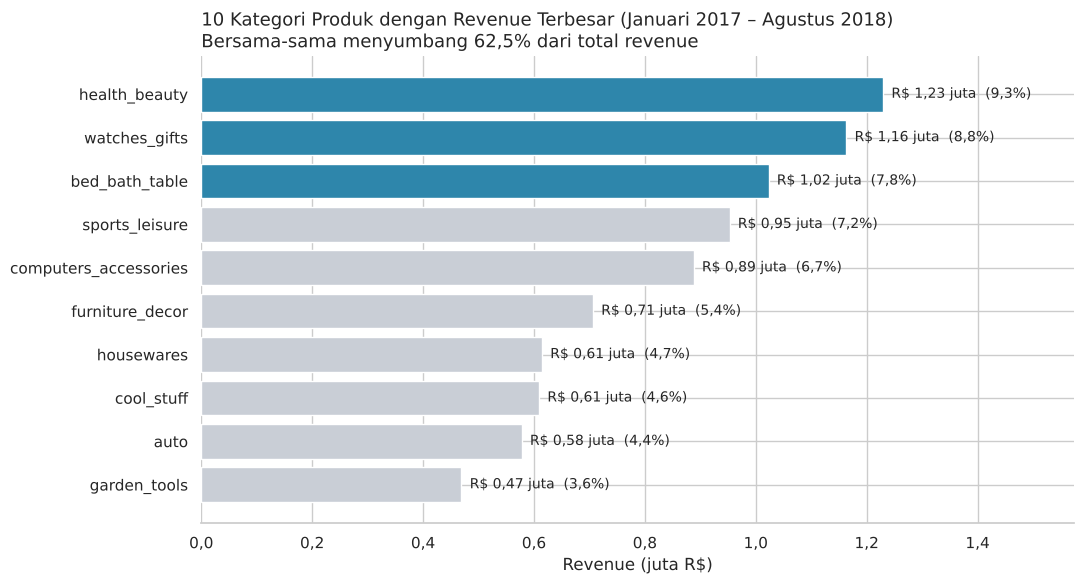

In [18]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_df = top10.reset_index().sort_values("revenue")
colors = ["#C9CED6"] * 7 + ["#2E86AB"] * 3          # tiga teratas disorot
ax.barh(plot_df["category"], plot_df["revenue"] / 1e6, color=colors)
for i, (rev, pct) in enumerate(zip(plot_df["revenue"], plot_df["pct_revenue"])):
    ax.text(rev / 1e6 + 0.015, i, f"R$ {fmt(rev/1e6, 2)} juta  ({fmt(pct, 1)}%)", va="center", fontsize=10)
ax.set_xlim(0, plot_df["revenue"].max() / 1e6 * 1.28)
ax.set_xlabel("Revenue (juta R$)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(v, 1)))
ax.set_ylabel("")
ax.set_title("10 Kategori Produk dengan Revenue Terbesar (Januari 2017 – Agustus 2018)\n"
             f"Bersama-sama menyumbang {fmt(top10['pct_revenue'].sum(), 1)}% dari total revenue", loc="left", fontsize=13)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight:**
- Tiga kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`) menyumbang ±26% revenue; 10 kategori teratas menyumbang ±62% dari total 74 kategori.
- `watches_gifts` unggul karena harga rata-rata per item tinggi (≈ R$ 199) meski jumlah pesanannya lebih sedikit daripada `bed_bath_table`, yang justru unggul dalam volume pesanan.
- Pendapatan terkonsentrasi pada sedikit kategori, sehingga performa kategori-kategori ini menentukan kesehatan bisnis secara keseluruhan.

### Pertanyaan 2
**Bagaimana tren jumlah pesanan dan revenue bulanan (Month-over-Month) selama Januari 2017 – Agustus 2018, serta pada bulan apa terjadi lonjakan tertinggi dan penurunan tertajam?**

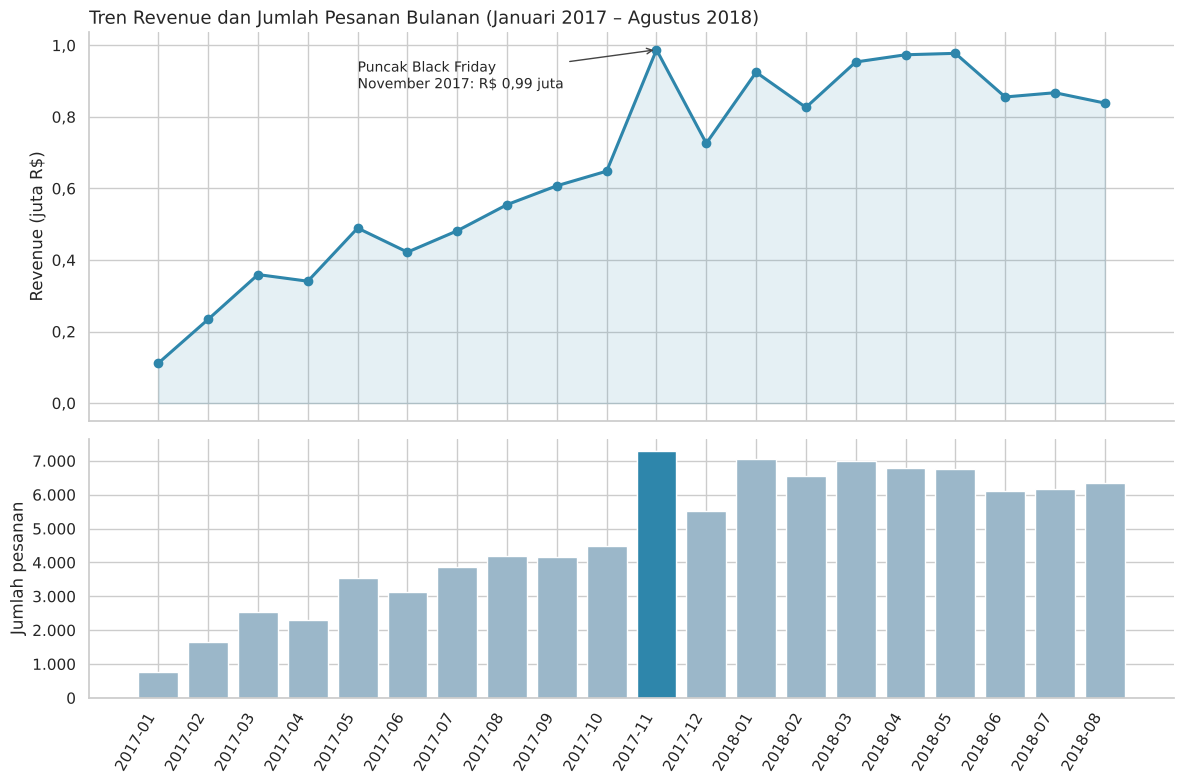

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

x = range(len(monthly_df))
axes[0].plot(x, monthly_df["revenue"] / 1e6, marker="o", color="#2E86AB", linewidth=2.2)
axes[0].fill_between(x, monthly_df["revenue"] / 1e6, alpha=0.12, color="#2E86AB")
i_peak = monthly_df["revenue"].idxmax()
axes[0].annotate(f"Puncak Black Friday\nNovember 2017: R$ {fmt(monthly_df.loc[i_peak, 'revenue'] / 1e6, 2)} juta",
                 xy=(i_peak, monthly_df.loc[i_peak, "revenue"] / 1e6), xytext=(i_peak - 6, 0.88),
                 arrowprops=dict(arrowstyle="->", color="#444"), fontsize=10)
axes[0].set_ylabel("Revenue (juta R$)")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt(v, 1)))
axes[0].set_title("Tren Revenue dan Jumlah Pesanan Bulanan (Januari 2017 – Agustus 2018)", loc="left", fontsize=13)

axes[1].bar(x, monthly_df["orders"], color="#9BB7C9")
axes[1].bar(i_peak, monthly_df.loc[i_peak, "orders"], color="#2E86AB")
axes[1].set_ylabel("Jumlah pesanan")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(monthly_df["order_month"], rotation=60, ha="right")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{fmt(v, 0)}"))
sns.despine()
plt.tight_layout()
plt.show()

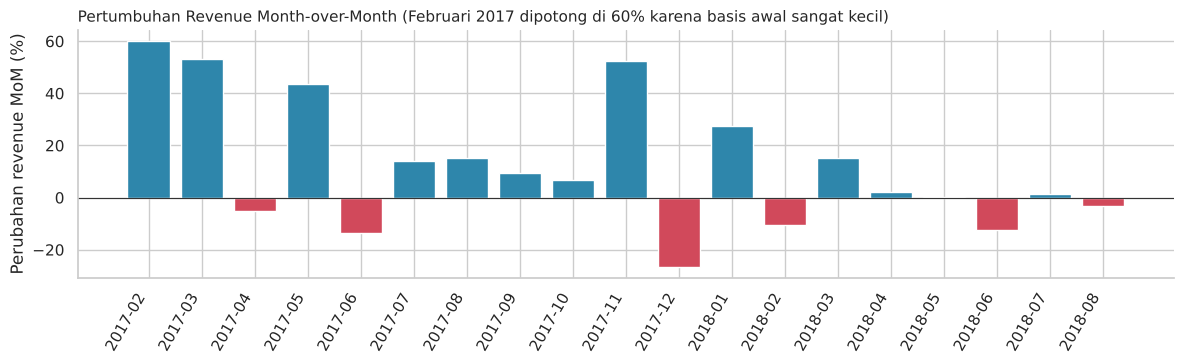

In [20]:
fig, ax = plt.subplots(figsize=(12, 3.8))
mom = monthly_df.iloc[1:]
ax.bar(mom["order_month"], mom["revenue_mom"].clip(upper=60), color=np.where(mom["revenue_mom"] >= 0, "#2E86AB", "#D1495B"))
ax.axhline(0, color="#333", linewidth=0.8)
ax.set_ylabel("Perubahan revenue MoM (%)")
ax.set_title("Pertumbuhan Revenue Month-over-Month (Februari 2017 dipotong di 60% karena basis awal sangat kecil)", loc="left", fontsize=11)
plt.xticks(rotation=60, ha="right")
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Revenue naik dari ±R$ 0,11 juta (Januari 2017) menjadi ±R$ 0,65 juta (Oktober 2017), lalu **melonjak 52% pada November 2017** ke R$ 0,99 juta, bulan tertinggi sepanjang periode, diikuti pesanan yang naik 63%. Pola ini konsisten dengan momentum Black Friday.
- **Penurunan tertajam terjadi Desember 2017 (-26,5%)**, yaitu efek normalisasi setelah puncak promosi.
- Sepanjang 2018 revenue mendatar di kisaran R$ 0,83–0,98 juta per bulan, dan pesanan cenderung turun dari ±7.000 (Januari–Maret) menjadi ±6.100–6.350 (Juni–Agustus). Pertumbuhan eksplosif 2017 belum berlanjut di 2018.

### Pertanyaan 3
**Di state mana rata-rata waktu pengiriman (hari sejak pembelian hingga diterima) paling lama dan persentase pesanan terlambat paling tinggi pada periode Januari 2017 – Agustus 2018?**

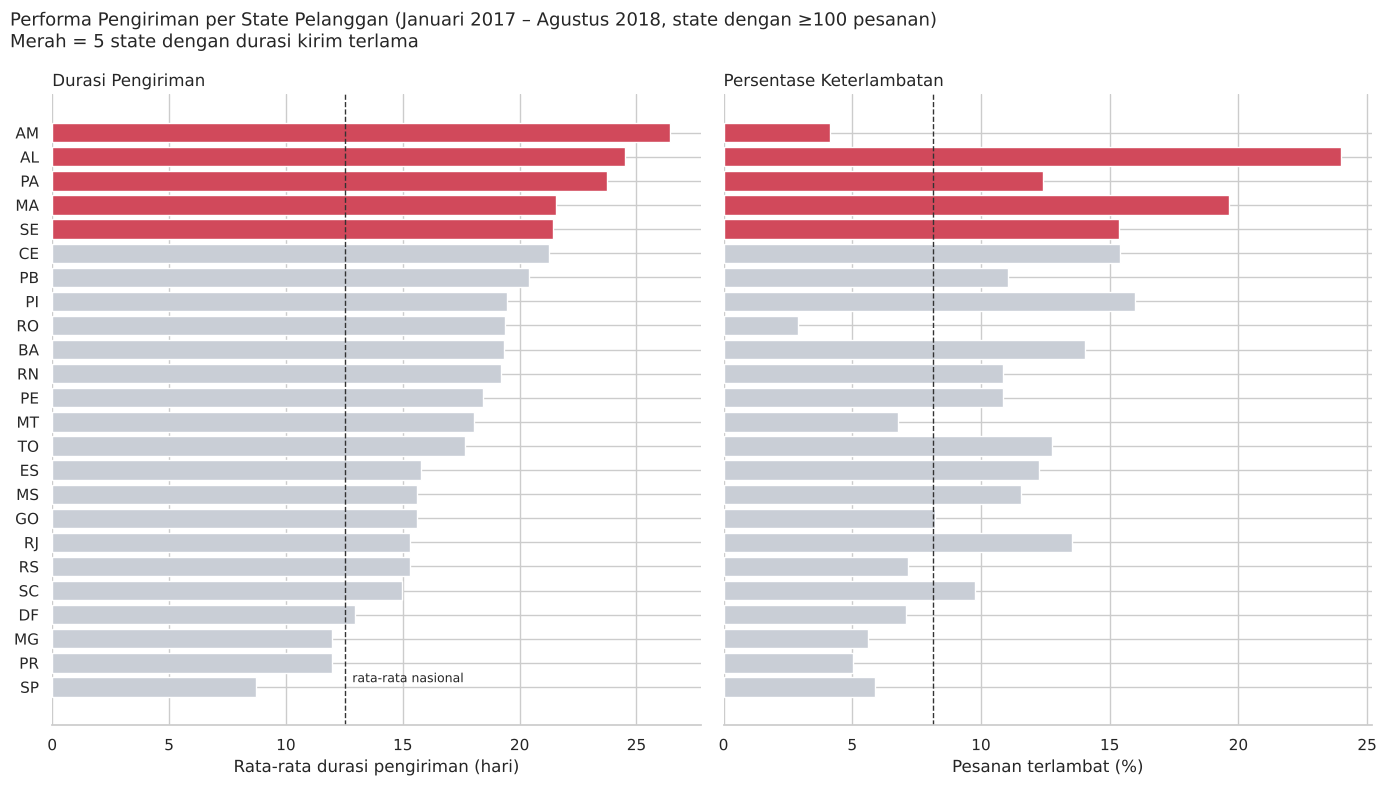

In [21]:
plot_state = state_ranked.sort_values("avg_delivery_days", ascending=True)
worst5 = set(state_ranked.nlargest(5, "avg_delivery_days")["customer_state"])
bar_colors = ["#D1495B" if s in worst5 else "#C9CED6" for s in plot_state["customer_state"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
axes[0].barh(plot_state["customer_state"], plot_state["avg_delivery_days"], color=bar_colors)
axes[0].axvline(order_df["delivery_days"].mean(), color="#333", linestyle="--", linewidth=1)
axes[0].text(order_df["delivery_days"].mean() + 0.3, 0.2, "rata-rata nasional", fontsize=9)
axes[0].set_xlabel("Rata-rata durasi pengiriman (hari)")
axes[0].set_title("Durasi Pengiriman", loc="left", fontsize=12)

axes[1].barh(plot_state["customer_state"], plot_state["late_pct"], color=bar_colors)
axes[1].axvline(order_df["is_late"].mean() * 100, color="#333", linestyle="--", linewidth=1)
axes[1].set_xlabel("Pesanan terlambat (%)")
axes[1].set_title("Persentase Keterlambatan", loc="left", fontsize=12)

fig.suptitle("Performa Pengiriman per State Pelanggan (Januari 2017 – Agustus 2018, state dengan ≥100 pesanan)\n"
             "Merah = 5 state dengan durasi kirim terlama", x=0.01, ha="left", fontsize=13)
sns.despine(left=True)
plt.tight_layout()
plt.show()

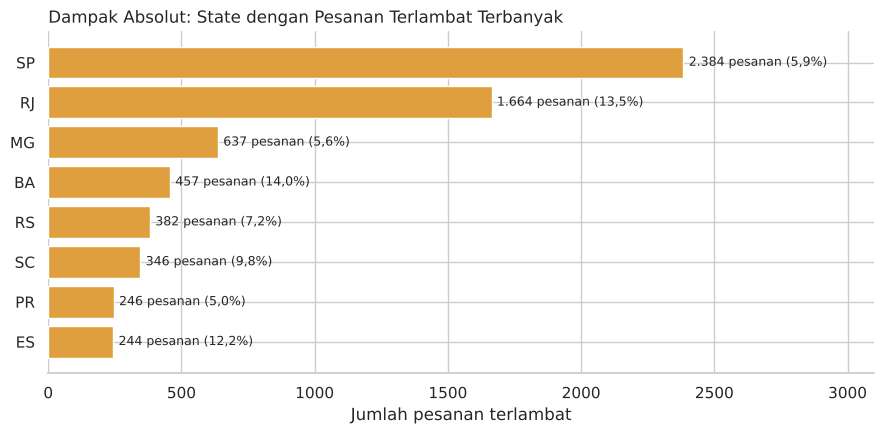

In [22]:
top_late = state_ranked.nlargest(8, "late_orders").sort_values("late_orders")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top_late["customer_state"], top_late["late_orders"], color="#E09F3E")
for i, (n, p) in enumerate(zip(top_late["late_orders"], top_late["late_pct"])):
    ax.text(n + 20, i, f"{fmt(n, 0)} pesanan ({fmt(p, 1)}%)", va="center", fontsize=9)
ax.set_xlim(0, top_late["late_orders"].max() * 1.3)
ax.set_xlabel("Jumlah pesanan terlambat")
ax.set_title("Dampak Absolut: State dengan Pesanan Terlambat Terbanyak", loc="left", fontsize=12)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight:**
- State dengan durasi kirim terlama (≥100 pesanan): **AM (±26,4 hari), AL (±24,5), PA (±23,8), MA (±21,5), SE (±21,4)**, jauh di atas rata-rata nasional ±12,5 hari dan SP ±8,7 hari. Wilayah utara dan timur laut jelas tertinggal. Catatan: AM lambat tetapi hanya ±4% yang terlambat, artinya estimasi pengirimannya sudah realistis, sedangkan AL ±24% terlambat.
- **AL memiliki persentase keterlambatan tertinggi (±24%)**, disusul MA (±19,6%) dan PI (±16%).
- Dari sisi dampak absolut, **SP dan RJ** menyumbang jumlah pesanan terlambat terbanyak karena volumenya sangat besar. RJ juga tinggi secara persentase (±13,5%), jauh di atas SP (±5,9%) dan MG (±5,6%). Rata-rata durasi kirim RJ (±15,3 hari) berada di atas rata-rata nasional ±12,5 hari, tetapi masih lebih singkat daripada state di utara dan timur laut.

## Analisis Lanjutan: RFM Analysis dengan Manual Grouping

**Tujuan:** mengelompokkan pelanggan berdasarkan perilaku belanja agar tim marketing dapat menentukan strategi retensi yang berbeda untuk tiap kelompok, tanpa memakai algoritma machine learning.

- **Recency:** jumlah hari sejak pembelian terakhir pelanggan (acuan: sehari setelah transaksi terakhir pada dataset)
- **Frequency:** jumlah pesanan unik per `customer_unique_id`
- **Monetary:** total `price` yang dibelanjakan

Karena ±97% pelanggan hanya berbelanja sekali, skor kuantil untuk Frequency tidak bermakna. Maka segmentasi dibuat dengan **aturan bisnis (manual grouping)**:

| Segmen | Aturan |
|--------|--------|
| Loyal Customer | Frequency ≥ 2 |
| High-Value Recent | Frequency = 1, Recency ≤ 180 hari, Monetary ≥ persentil 75 |
| New Customer | Frequency = 1, Recency ≤ 180 hari, Monetary < persentil 75 |
| Need Attention | Frequency = 1, Recency 181–365 hari |
| Lost Customer | Frequency = 1, Recency > 365 hari |

In [23]:
snapshot_date = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = (main_df.groupby("customer_unique_id")
          .agg(last_purchase=("order_purchase_timestamp", "max"),
               frequency=("order_id", "nunique"),
               monetary=("price", "sum"))
          .reset_index())
rfm_df["recency"] = (snapshot_date - rfm_df["last_purchase"]).dt.days

p75 = rfm_df["monetary"].quantile(0.75)

def assign_segment(row):
    if row["frequency"] >= 2:
        return "Loyal Customer"
    if row["recency"] <= 180:
        return "High-Value Recent" if row["monetary"] >= p75 else "New Customer"
    if row["recency"] <= 365:
        return "Need Attention"
    return "Lost Customer"

rfm_df["segment"] = rfm_df.apply(assign_segment, axis=1)

print(f"Persentil 75 monetary: R$ {fmt(p75, 2)}")
print(f"Pelanggan dengan frequency = 1: {fmt((rfm_df['frequency'] == 1).mean()*100, 1)}%")
rfm_df[["recency", "frequency", "monetary"]].describe()

Persentil 75 monetary: R$ 154,16
Pelanggan dengan frequency = 1: 97,0%


,recency,frequency,monetary
count,"93.096,00","93.096,00","93.096,00"
mean,"236,71","1,03","141,57"
std,"150,94","0,21","215,77"
min,"1,00","1,00","0,85"
25%,"114,00","1,00","47,65"
50%,"218,00","1,00","89,70"
75%,"345,00","1,00","154,16"
max,"602,00","15,00","13.440,00"


In [24]:
segment_df = (rfm_df.groupby("segment")
              .agg(customers=("customer_unique_id", "count"),
                   avg_recency=("recency", "mean"),
                   avg_monetary=("monetary", "mean"),
                   total_monetary=("monetary", "sum"))
              .reset_index())
segment_df["pct_customers"] = segment_df["customers"] / segment_df["customers"].sum() * 100
segment_df["pct_revenue"] = segment_df["total_monetary"] / segment_df["total_monetary"].sum() * 100
order = ["High-Value Recent", "New Customer", "Need Attention", "Lost Customer", "Loyal Customer"]
segment_df = segment_df.set_index("segment").loc[order].reset_index()
segment_df

,segment,customers,avg_recency,avg_monetary,total_monetary,pct_customers,pct_revenue
0,High-Value Recent,8870,"93,46","357,97","3.175.237,15","9,53","24,09"
1,New Customer,27999,"91,77","71,30","1.996.213,84","30,08","15,15"
2,Need Attention,33446,"263,55","136,02","4.549.219,87","35,93","34,52"
3,Lost Customer,19992,"460,74","136,74","2.733.752,05","21,47","20,74"
4,Loyal Customer,2789,"219,60","260,08","725.355,04","3,00","5,50"


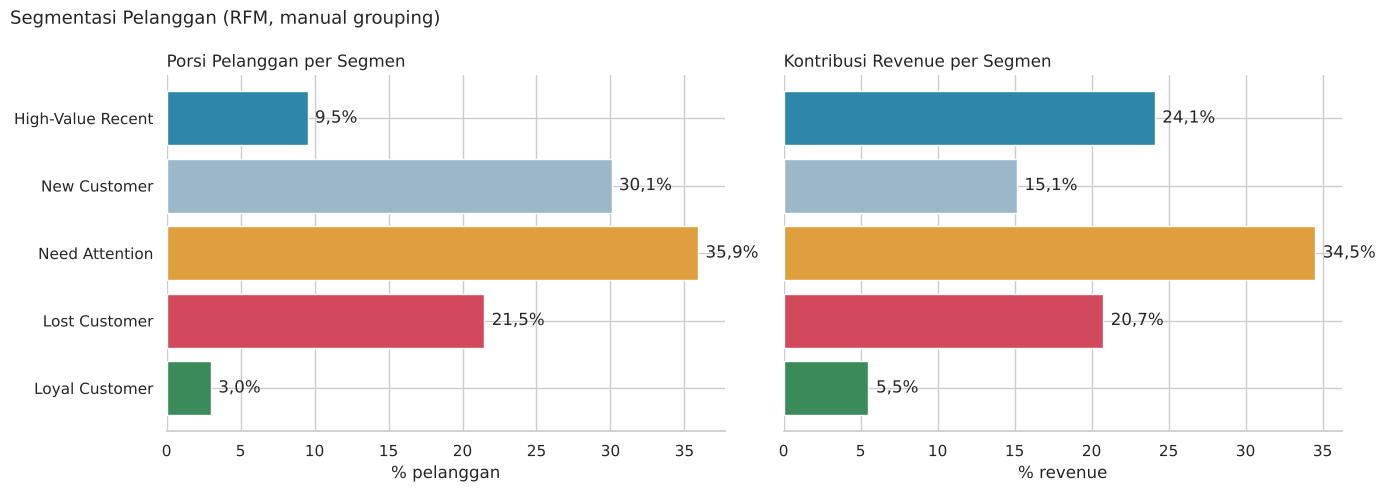

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
palette = {"High-Value Recent": "#2E86AB", "New Customer": "#9BB7C9", "Need Attention": "#E09F3E",
           "Lost Customer": "#D1495B", "Loyal Customer": "#3B8B5A"}
cols = [palette[s] for s in segment_df["segment"]]

axes[0].barh(segment_df["segment"], segment_df["pct_customers"], color=cols)
for i, v in enumerate(segment_df["pct_customers"]):
    axes[0].text(v + 0.5, i, f"{fmt(v, 1)}%", va="center")
axes[0].set_title("Porsi Pelanggan per Segmen", loc="left", fontsize=12)
axes[0].set_xlabel("% pelanggan")
axes[0].invert_yaxis()

axes[1].barh(segment_df["segment"], segment_df["pct_revenue"], color=cols)
for i, v in enumerate(segment_df["pct_revenue"]):
    axes[1].text(v + 0.5, i, f"{fmt(v, 1)}%", va="center")
axes[1].set_title("Kontribusi Revenue per Segmen", loc="left", fontsize=12)
axes[1].set_xlabel("% revenue")

fig.suptitle("Segmentasi Pelanggan (RFM, manual grouping)", x=0.01, ha="left", fontsize=13)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight RFM:**
- Hanya **±3% pelanggan** yang pernah membeli lebih dari sekali (**Loyal Customer**), dan kelompok ini menyumbang ±5,5% revenue. Retensi sangat lemah.
- **Need Attention (±36%) dan Lost Customer (±21%)** adalah kelompok pelanggan satu kali beli yang sudah lebih dari 6 bulan tidak kembali; keduanya bersama-sama mencakup lebih dari separuh basis pelanggan dan ±55% total belanja.
- **High-Value Recent** hanya ±9,5% pelanggan tetapi menyumbang ±24% revenue sehingga merupakan target utama untuk program loyalitas sebelum berpindah ke segmen Need Attention.

## Conclusion

**Kesimpulan Pertanyaan 1:**
*Kategori produk apa saja yang menjadi 10 penyumbang revenue terbesar pada pesanan delivered periode Januari 2017 – Agustus 2018, dan berapa persen kontribusinya terhadap total revenue?*

10 kategori teratas, dipimpin `health_beauty` (±9,3%), `watches_gifts` (±8,8%), dan `bed_bath_table` (±7,8%), menyumbang ±62% dari total revenue R$ 13,18 juta. Pendapatan sangat terkonsentrasi; `watches_gifts` kuat karena nilai per item yang tinggi, sedangkan `bed_bath_table` kuat karena volume.

**Kesimpulan Pertanyaan 2:**
*Bagaimana tren jumlah pesanan dan revenue bulanan (Month-over-Month) selama Januari 2017 – Agustus 2018, serta pada bulan apa terjadi lonjakan tertinggi dan penurunan tertajam?*

Revenue dan pesanan tumbuh pesat sepanjang 2017 dan mencapai puncak pada **November 2017** (±R$ 0,99 juta; +52% MoM), lalu turun tajam di Desember 2017 (-26,5%). Sepanjang 2018 pertumbuhan mendatar di kisaran R$ 0,83–0,98 juta per bulan dengan jumlah pesanan yang cenderung menurun pada pertengahan 2018.

**Kesimpulan Pertanyaan 3:**
*Di state mana rata-rata waktu pengiriman (hari sejak pembelian hingga diterima) paling lama dan persentase pesanan terlambat paling tinggi pada periode Januari 2017 – Agustus 2018?*

Pengiriman di wilayah utara dan timur laut jauh lebih lambat (AM, AL, PA, MA, SE: ±21–26 hari dibandingkan dengan rata-rata nasional ±12,5 hari). AL, MA, dan PI memiliki persentase keterlambatan tertinggi (AM lambat namun jarang terlambat karena estimasinya longgar), sedangkan SP dan RJ menyumbang jumlah pesanan terlambat terbanyak karena volumenya; RJ juga tinggi secara persentase (±13,5%).

**Kesimpulan Analisis Lanjutan (RFM):**
Basis pelanggan didominasi pembeli satu kali (±97%). Segmen Need Attention dan Lost Customer mencakup ±57% pelanggan, sementara segmen Loyal hanya ±3%.

### Rekomendasi (Action Items)
1. **Fokus promosi dan akuisisi seller pada kategori bernilai tinggi:** prioritaskan `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories`. Gunakan strategi bundling untuk kategori volume tinggi dan promosi premium untuk kategori bernilai per item tinggi.
2. **Rencanakan kampanye dan kapasitas logistik menjelang November:** siapkan stok, kapasitas kurir, dan kampanye Black Friday mulai Oktober; siapkan program lanjutan di Desember agar penurunan pasca-puncak tidak setajam Desember 2017. Untuk mengatasi stagnasi 2018, dorong kampanye di bulan non-puncak (misalnya Maret–Mei dan Juni–Agustus).
3. **Perbaiki logistik berdasarkan wilayah:** (a) negosiasi atau tambah mitra kurir untuk **AL, MA, PI, PA, SE, CE** (lambat dan/atau sering terlambat) dan evaluasi estimasi pengiriman yang terlalu optimis; untuk **AM**, estimasi sudah realistis sehingga fokusnya mempercepat rute; (b) pertimbangkan gudang atau *fulfillment center* regional untuk wilayah utara/timur laut; (c) audit proses pengiriman di **RJ** karena volumenya besar dan keterlambatannya 13,5%.
4. **Tingkatkan retensi pelanggan:** kirim voucher *repeat purchase* kepada segmen **Need Attention** (pembelian terakhir 6–12 bulan lalu), kampanye *win-back* untuk **Lost Customer**, dan program loyalitas khusus untuk **High-Value Recent** agar mereka melakukan pembelian kedua.